# Cross-segment comparability: what survives the provider break?

The activity data come from three mobile-data providers, one per period. There is **no overlap**: each provider
only has data for its own months, so there is nothing to calibrate one against another. That means absolute
levels cannot be bridged across a break, and anything we say across the break has to be tested rather than assumed.

| Segment | Months | Reference Bay home panel | Status |
|---|---|---|---|
| S1 | Jan 2019 - Dec 2022 | ~211,000 devices | used |
| S2 | Jan - Jun 2023 | ~17,000 devices | **excluded** (tested below) |
| S3 | Jul 2023 - Dec 2025 | ~2,290,000 devices | used |

This notebook tests four things and writes the result as a small set of **rules** that `05_corridor_metrics`
carries into the front-end data:

1. **Is S2 usable?** (No: too small and noisy. It is excluded everywhere.)
2. **Is the provider effect a common multiplier?** If every corridor were scaled by the same factor at the break,
   relative measures such as a corridor's *share of the 21-corridor total* would be break-proof. We measure how
   far from "common" it is, and turn the excess spread into an uncertainty band to draw at the break.
3. **Which metrics keep their corridor ranking across the break?** A metric whose ranking survives can be shown as
   "position among peers"; one whose ranking does not must stay within-segment.
4. **Do S1 and S3 agree on *where* visitors live?** This decides whether the pooled origin maps (S1/S3 equal-weighted)
   are defensible.

**How "natural" variation is separated from provider effects.** For each test we compare the spread across
the break (S1 -> S3) with the spread over a comparable gap *inside* a segment (S1: 2021 -> 2022; S3: 2024 -> 2025).
Real corridor-level change also shows up in the cross-break spread, so the cross-break numbers are an **upper bound**
on the provider effect, and any band derived from them is deliberately conservative. With only 21 corridors every
estimate has real sampling error, which is why a bootstrap interval is shown for the headline correlations.

---

| | |
|---|---|
| **Inputs** | `data/activity/processed/*` (from `01_`-`03_`) |
| **Outputs** | `data/activity/processed/comparability.json` (rules and band parameters used by `05_`) |
| **Run after** | `01_` ... `03_` |

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="Unable to import Axes3D")

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# --- Paths ---
# Repo root = nearest parent folder containing package.json, so this notebook runs from any depth.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"                 # raw + intermediate files
SRC_DATA = ROOT / "src" / "data"     # final outputs consumed directly by the web app
PROCESSED_DIR = DATA / "activity" / "processed"

STOPS_CSV = PROCESSED_DIR / "corridor_stops.csv.gz"
REPEAT_CSV = PROCESSED_DIR / "corridor_repeat_visitors.csv.gz"
ORIGIN_CATEGORY_CSV = PROCESSED_DIR / "corridor_origin_categories_monthly.csv.gz"
DISTANCE_CSV = PROCESSED_DIR / "corridor_home_distance_monthly.csv.gz"
HOMES_CSV = PROCESSED_DIR / "corridor_homes.csv.gz"
HOME_GEOGRAPHY_CSV = PROCESSED_DIR / "home_geography.csv.gz"
BAY_DENOMS_CSV = PROCESSED_DIR / "bay_month_denoms.csv.gz"
CROSSWALK_CSV = PROCESSED_DIR / "bg_crosswalk_2010_to_2020.csv.gz"
BG_DISTRICT_CSV = PROCESSED_DIR / "bg_district_weights.csv"
CORRIDOR_DISTRICT_CSV = PROCESSED_DIR / "corridor_districts.csv"
CORRIDOR_LOOKUP_CSV = PROCESSED_DIR / "corridor_lookup.csv"
COMPARABILITY_JSON = PROCESSED_DIR / "comparability.json"

# --- Parameters ---
TIME_PERIODS = ["all", "evening", "nine-five", "weekdays", "weekends"]
VALUE_COL = "normalized_unique_device_months"
UNMATCHED_BG = "UNKNOWN"
ORIGIN_CATEGORIES = ["Oakland", "San Francisco", "Rest East Bay", "Rest Bay Area"]
UNKNOWN_DISTANCE = "Unknown distance"

# Comparison windows. "H2" (Jul-Dec) windows keep the season fixed across the break; 2023H2 is the first S3 half-year.
S1_WITHIN = ("2021", 7), ("2022", 7)          # (year, first month): H2 2021 -> H2 2022
S3_WITHIN = ("2024", 7), ("2025", 7)          # H2 2024 -> H2 2025
BREAK = ("2022", 7), ("2023", 7)              # H2 2022 (S1) -> H2 2023 (S3): the adjacent half-years across the break
# Rank-stability windows: the H2 (Jul-Dec) of a year, so every comparison has the same one-year gap and the same season
H2_WITHIN_S1 = ("2021", "2022")
H2_BREAK = ("2022", "2023")                   # last S1 H2 -> first S3 H2
H2_WITHIN_S3 = ("2024", "2025")

RANK_OK_THRESHOLD = 0.90          # a metric is "peer_relative" across the break if its corridor ranking keeps rho >= this
N_BOOT = 2000
RNG_SEED = 7
ROBUST_SD = 1.4826                # MAD -> SD for normally distributed data

# --- Chart styling (see dataviz skill: fixed categorical order, single-hue sequential) ---
CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
CHART_GRID_COLOR = "#e1e0d9"
CHART_MUTED_TEXT = "#898781"

In [3]:
def style_axis(ax, grid_axis="y"):
    """Shared cosmetic cleanup: recessive grid, no top/right spines."""
    ax.grid(axis=grid_axis, color=CHART_GRID_COLOR, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=CHART_MUTED_TEXT)


def robust_sd(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return float(ROBUST_SD * np.median(np.abs(x - np.median(x))))


def window_mean(frame, year, first_month, n_months=6):
    """Mean over n_months starting at (year, first_month) of a month x corridor frame indexed by 'YYYYMM' strings."""
    start = f"{year}{first_month:02d}"
    i = frame.index.get_loc(start)
    return frame.iloc[i:i + n_months].mean()


def year_mean(frame, year):
    return frame[[m.startswith(year) for m in frame.index]].mean()


def rank_rho(a, b):
    return float(spearmanr(a, b)[0])


def boot_rho_ci(a, b, rng):
    a, b = np.asarray(a), np.asarray(b)
    n = len(a)
    out = []
    for _ in range(N_BOOT):
        idx = rng.integers(0, n, n)
        if len(set(idx)) > 2:
            out.append(spearmanr(a[idx], b[idx])[0])
    return [float(np.nanpercentile(out, 2.5)), float(np.nanpercentile(out, 97.5))]

## Load data

In [4]:
stops = pd.read_csv(STOPS_CSV)
stops["year_month"] = stops.year_month.astype(str)
repeat = pd.read_csv(REPEAT_CSV)
origin_cat = pd.read_csv(ORIGIN_CATEGORY_CSV)
origin_cat["year"] = origin_cat.year_month.astype(str).str[:4]
origin_cat["month"] = origin_cat.year_month % 100
distance = pd.read_csv(DISTANCE_CSV)
distance["year"] = distance.year_month.astype(str).str[:4]
distance["month"] = distance.year_month % 100
bay = pd.read_csv(BAY_DENOMS_CSV)
bay["year_month"] = bay.year_month.astype(str)
lookup = pd.read_csv(CORRIDOR_LOOKUP_CSV)
slugs = lookup.corridor_slug.tolist()
months = sorted(stops.year_month.unique())


def monthly_frame(col, period="all"):
    return stops[stops.time_period == period].pivot(index="year_month", columns="corridor_slug", values=col).reindex(months)[slugs]


dev = monthly_frame("adjusted_known_home_unique_devices")
vis = monthly_frame("adjusted_known_home_visits")
raw_dev = monthly_frame("unique_devices")
seg_of_month = stops.drop_duplicates("year_month").set_index("year_month").provider_segment.reindex(months)
print(f"{len(slugs)} corridors, {len(months)} months")

21 corridors, 84 months


## 1. Is S2 usable?

S2 is a six-month, ~17k-device panel from a different provider. The sample is two orders of magnitude smaller than the
other segments, and its reference period (the first up to 12 months used to scale the weights) is only six months
long. The table and chart show what that means for a corridor.

,months,reference_panel_devices,median_corridor_raw_devices_per_month,min_corridor_raw_devices_per_month,median_corridor_adjusted_devices
segment,,,,,
S1_LIMA,48,211000,2037,406,1367
S2_SIERRA,6,16717,117,34,86
S3_PAPA,30,2291930,7936,934,3298


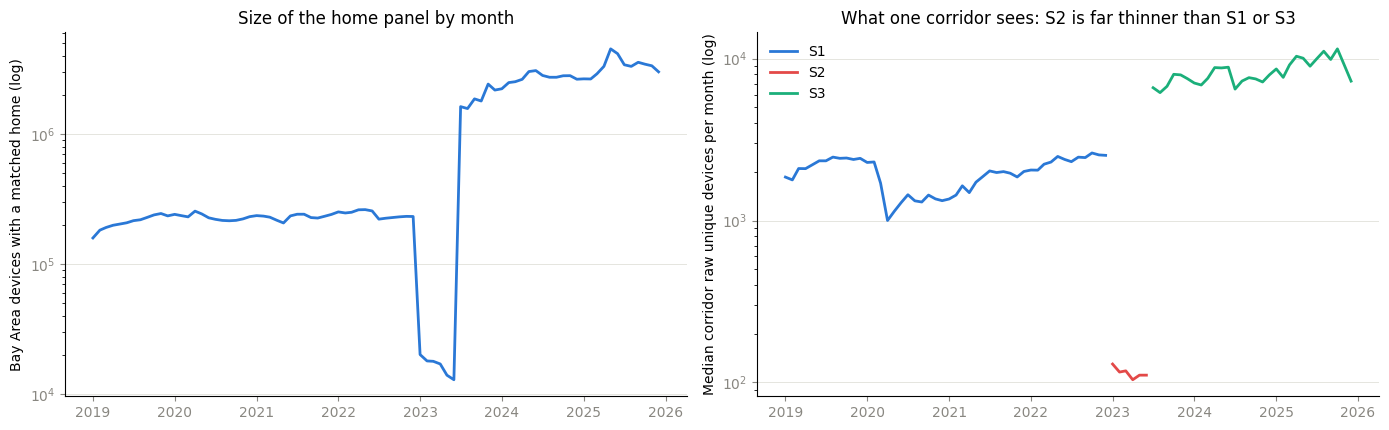

In [5]:
rows = []
for seg, g in seg_of_month.groupby(seg_of_month):
    m = g.index
    panel = bay[bay.year_month.isin(m)].baseline_bay_home_sample.iloc[0]
    rows.append({
        "segment": seg, "months": len(m), "reference_panel_devices": int(panel),
        "median_corridor_raw_devices_per_month": int(raw_dev.loc[m].median().median()),
        "min_corridor_raw_devices_per_month": int(raw_dev.loc[m].median().min()),
        "median_corridor_adjusted_devices": int(dev.loc[m].median().median()),
    })
seg_table = pd.DataFrame(rows).set_index("segment")
display(seg_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
bay_dt = pd.to_datetime(bay.year_month, format="%Y%m")
axes[0].plot(bay_dt, bay.bay_home_sample, color=CATEGORICAL_PALETTE[0], linewidth=2)
axes[0].set_yscale("log")
axes[0].set_ylabel("Bay Area devices with a matched home (log)")
axes[0].set_title("Size of the home panel by month")
style_axis(axes[0])

med = raw_dev.median(axis=1)
colors = {"S1_LIMA": CATEGORICAL_PALETTE[0], "S2_SIERRA": CATEGORICAL_PALETTE[7], "S3_PAPA": CATEGORICAL_PALETTE[2]}
for seg, g in seg_of_month.groupby(seg_of_month):
    axes[1].plot(pd.to_datetime(g.index, format="%Y%m"), med.loc[g.index], color=colors[seg], linewidth=2, label=seg.split("_")[0])
axes[1].set_yscale("log")
axes[1].set_ylabel("Median corridor raw unique devices per month (log)")
axes[1].set_title("What one corridor sees: S2 is far thinner than S1 or S3")
axes[1].legend(frameon=False)
style_axis(axes[1])
plt.tight_layout()
plt.show()

**Decision: S2 is excluded** from every series, share and pooled map. With a few hundred devices a month its values
are dominated by sampling noise, and six months of reference is too short to estimate weights reliably. The months
stay in the arrays as `null` so charts show an honest gap, not a bridge.

## 2. Is the provider effect a common multiplier?

If the effect of switching provider were the **same factor in every corridor**, then a corridor's *share of the
21-corridor total* would pass through the break unchanged, and the break would only move the overall scale. To test
this, take each corridor's log-ratio of activity between two half-years (H2 to H2, to hold the season fixed):

- **inside S1** (H2 2021 -> H2 2022), **inside S3** (H2 2024 -> H2 2025): ordinary change plus sampling noise;
- **across the break** (H2 2022 -> H2 2023): ordinary change plus the provider effect.

The *median* log-ratio is the overall scale shift (not separable from real change, so it is never used). The
*robust spread across corridors* (1.4826 x median absolute deviation, so a couple of tiny corridors can't dominate)
measures how unequal the effect is between corridors. If the cross-break spread is about the same as the
within-segment spread, the effect is close to a common multiplier.

In [6]:
def log_ratio(frame, w_from, w_to):
    return np.log(window_mean(frame, *w_to) / window_mean(frame, *w_from))


def share_of_total(frame):
    return frame.div(frame.sum(axis=1), axis=0) * 100


vpd = vis / dev
measures = {
    "Estimated devices (level)": dev,
    "Estimated visits (level)": vis,
    "Visits per device": vpd,
    "Share of 21-corridor total (devices)": share_of_total(dev),
}

rows, lr_store = [], {}
for name, frame in measures.items():
    r_s1 = log_ratio(frame, *S1_WITHIN)
    r_s3 = log_ratio(frame, *S3_WITHIN)
    r_br = log_ratio(frame, *BREAK)
    lr_store[name] = (r_s1, r_s3, r_br)
    within_sd = np.sqrt((robust_sd(r_s1) ** 2 + robust_sd(r_s3) ** 2) / 2)
    rows.append({
        "measure": name,
        "median x within S1": np.exp(r_s1.median()), "median x within S3": np.exp(r_s3.median()), "median x ACROSS break": np.exp(r_br.median()),
        "spread within (robust SD, log)": within_sd, "spread across break": robust_sd(r_br),
        "excess spread": float(np.sqrt(max(0.0, robust_sd(r_br) ** 2 - within_sd ** 2))),
    })
level_table = pd.DataFrame(rows).set_index("measure")
display(level_table.round(3))

,median x within S1,median x within S3,median x ACROSS break,"spread within (robust SD, log)",spread across break,excess spread
measure,,,,,,
Estimated devices (level),1.264,0.978,1.817,0.079,0.355,0.346
Estimated visits (level),1.290,1.052,1.422,0.112,0.305,0.284
Visits per device,0.985,1.097,0.766,0.053,0.131,0.119
Share of 21-corridor total (devices),0.959,1.061,0.925,0.077,0.356,0.348


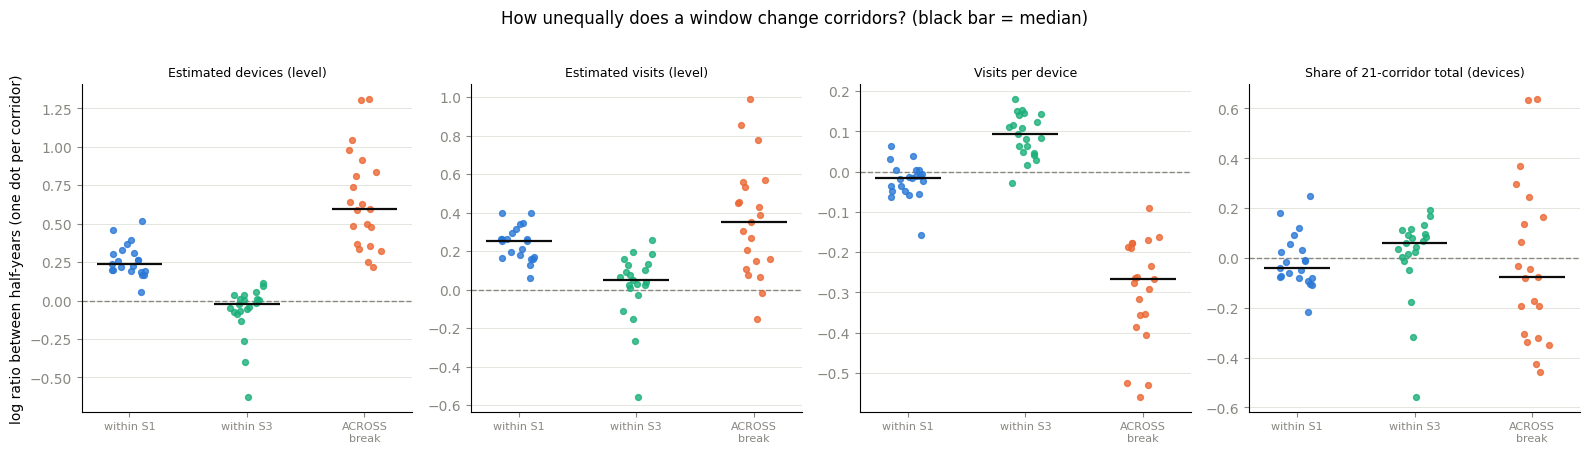

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (name, (r_s1, r_s3, r_br)) in zip(axes, lr_store.items()):
    for i, (vals, color) in enumerate([(r_s1, CATEGORICAL_PALETTE[0]), (r_s3, CATEGORICAL_PALETTE[2]), (r_br, CATEGORICAL_PALETTE[1])]):
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(vals))
        ax.scatter(np.full(len(vals), i) + jitter, vals, color=color, s=18, alpha=0.8, zorder=3)
        ax.hlines(vals.median(), i - 0.28, i + 0.28, color="#0b0b0b", linewidth=1.6, zorder=4)
    ax.set_xticks(range(3), ["within S1", "within S3", "ACROSS\nbreak"], fontsize=8)
    ax.axhline(0, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
    ax.set_title(name, fontsize=9)
    style_axis(ax)
axes[0].set_ylabel("log ratio between half-years (one dot per corridor)")
plt.suptitle("How unequally does a window change corridors? (black bar = median)", y=1.02)
plt.tight_layout()
plt.show()

**Reading this.** The levels shift by a large factor at the break, and *visits* shift by a different factor than
*devices*, so visits per device changes: the providers differ in how many pings per device they record, not only in
how many devices they see. The corridor-to-corridor spread across the break is larger than the ordinary
within-segment spread, so the provider effect is **not** a common multiplier. Even a corridor's share of the total
moves more across the break than inside a segment.

That is why the front end shows absolute levels as separate S1 and S3 lines, and shows the cross-break comparison
as a *share of the total* with an explicit band. The band width is the **excess spread** (last column). It is
conservative, because real post-pandemic divergence between corridors is included in it.

## 3. Which metrics keep their corridor ranking across the break?

For each metric compute a per-corridor value in the **second half (Jul-Dec)** of the years being compared, so each
comparison spans the same one-year gap in the same season: H2 2021 vs H2 2022 (inside S1), H2 2022 vs H2 2023 (across
the break) and H2 2024 vs H2 2025 (inside S3). Then take the Spearman rank correlation over the 21 corridors. A metric whose ranking is
**nearly as stable across the break as inside a segment** can be reported as the corridor's *position among its peers*
in each segment, and that position compared across the break. If the ranking breaks down, comparisons stay
within a segment.

In [8]:
homes = pd.read_csv(HOMES_CSV, dtype={"block_group_id": str},
                    usecols=["corridor_slug", "half_year", "time_period", "block_group_id", "provider_segment", VALUE_COL])
homes = homes[(homes.time_period == "all") & (homes.block_group_id != UNMATCHED_BG) & (homes.provider_segment != "S2_SIERRA")]
home_geo = pd.read_csv(HOME_GEOGRAPHY_CSV, dtype={"geoid": str})
homes = homes.merge(home_geo[["block_group_id", "geoid"]], on="block_group_id", how="left")
homes["geoid"] = homes.geoid.str.zfill(12)
homes["year"] = homes.half_year.str[:4]
homes["half"] = homes.half_year.str[4:]
homes["segment"] = homes.provider_segment.str.split("_").str[0]

crosswalk = pd.read_csv(CROSSWALK_CSV, dtype={"src_geoid": str, "tgt_geoid": str})
bg_district = pd.read_csv(BG_DISTRICT_CSV, dtype={"bg_geoid": str})
oak_ids = sorted(bg_district.bg_geoid.unique())
primary = pd.read_csv(CORRIDOR_DISTRICT_CSV).set_index("corridor_slug").primary_district.reindex(slugs)

# block group x district weight matrix
W = bg_district.pivot(index="bg_geoid", columns="district", values="weight").reindex(oak_ids).fillna(0)


def bg_share(h):
    """Corridor x Oakland-BG shares (% of that corridor's matched-home activity) for a subset of the home table."""
    a = h.groupby(["corridor_slug", "geoid"], as_index=False)[VALUE_COL].sum()
    total = a.groupby("corridor_slug")[VALUE_COL].sum()
    m = a.merge(crosswalk, left_on="geoid", right_on="src_geoid")
    m["alloc"] = m[VALUE_COL] * m.weight
    g = m.groupby(["corridor_slug", "tgt_geoid"]).alloc.sum().unstack().reindex(index=slugs, columns=oak_ids).fillna(0)
    return g.div(total.reindex(slugs), axis=0) * 100


def in_district_pct(share_df):
    d = share_df.values @ W.values
    cols = list(W.columns)
    return pd.Series([d[i, cols.index(primary[s])] for i, s in enumerate(slugs)], index=slugs)

In [9]:
def h2_metrics(year):
    out = {}
    out["Share of 21-corridor total (devices)"] = share_of_total(window_mean(dev, year, 7).to_frame().T).iloc[0]
    oc = origin_cat[(origin_cat.time_period == "all") & (origin_cat.year == year) & (origin_cat.month >= 7) & origin_cat.home_geography.isin(ORIGIN_CATEGORIES)]
    oc = oc.groupby(["corridor_slug", "home_geography"]).normalized_unique_devices.sum().unstack()
    out["Oakland share of visitors"] = (oc["Oakland"] / oc.sum(axis=1) * 100).reindex(slugs)

    d = distance[(distance.time_period == "all") & (distance.year == year) & (distance.month >= 7) & (distance.distance_band != UNKNOWN_DISTANCE)]
    band = d.groupby(["corridor_slug", d.distance_band.str[:2]]).normalized_unique_devices.sum().unstack()
    band = band.div(band.sum(axis=1), axis=0) * 100
    out["Share of visitors within 5 km"] = (band["00"] + band["01"]).reindex(slugs)
    out["Share of visitors beyond 25 km"] = band[["04", "05", "06"]].sum(axis=1).reindex(slugs)

    s = stops[stops.year_month.str.startswith(year) & (stops.year_month.str[4:].astype(int) >= 7) & stops.time_period.isin(["weekdays", "weekends", "nine-five", "evening"])]
    t = s.groupby(["corridor_slug", "time_period"]).adjusted_known_home_visits.sum().unstack()
    out["Weekend share of visits"] = (t["weekends"] / (t["weekdays"] + t["weekends"]) * 100).reindex(slugs)
    out["Evening share (evening vs weekday daytime)"] = (t["evening"] / (t["evening"] + t["nine-five"]) * 100).reindex(slugs)

    r = repeat[(repeat.time_period == "all") & (repeat.half_year == f"{year}H2")].groupby("corridor_slug").repeat_device_prop.mean() * 100
    out["Repeat-visitor %"] = r.reindex(slugs)

    out["Share from corridor's own council district"] = in_district_pct(bg_share(homes[(homes.year == year) & (homes.half == "H2")]))
    return pd.DataFrame(out)


annual = {y: h2_metrics(y) for y in tqdm(sorted(set(H2_WITHIN_S1 + H2_BREAK + H2_WITHIN_S3)), desc="H2 metrics")}

H2 metrics:   0%|          | 0/5 [00:00<?, ?it/s]

In [10]:
rng = np.random.default_rng(RNG_SEED)
rank_rows = {}
for metric in annual[H2_BREAK[0]].columns:
    a1, b1 = annual[H2_WITHIN_S1[0]][metric], annual[H2_WITHIN_S1[1]][metric]
    a2, b2 = annual[H2_BREAK[0]][metric], annual[H2_BREAK[1]][metric]
    a3, b3 = annual[H2_WITHIN_S3[0]][metric], annual[H2_WITHIN_S3[1]][metric]
    rho_s1, rho_br, rho_s3 = rank_rho(a1, b1), rank_rho(a2, b2), rank_rho(a3, b3)
    lo, hi = boot_rho_ci(a2, b2, rng)
    rank_rows[metric] = {
        "within S1 (H2 21 vs 22)": rho_s1, "ACROSS break (H2 22 vs 23)": rho_br, "95% CI (bootstrap)": f"[{lo:.2f}, {hi:.2f}]",
        "within S3 (H2 24 vs 25)": rho_s3, "median shift at break": float((b2 - a2).median()),
        "spread (SD) S1 -> S3": f"{a2.std():.1f} -> {b2.std():.1f}",
        "rule": "peer_relative" if rho_br >= RANK_OK_THRESHOLD else "within_segment_only",
    }
rank_table = pd.DataFrame(rank_rows).T
view = rank_table.copy()
for c in ["within S1 (H2 21 vs 22)", "ACROSS break (H2 22 vs 23)", "within S3 (H2 24 vs 25)", "median shift at break"]:
    view[c] = view[c].astype(float).round(2)
view

,within S1 (H2 21 vs 22),ACROSS break (H2 22 vs 23),95% CI (bootstrap),within S3 (H2 24 vs 25),median shift at break,spread (SD) S1 -> S3,rule
Share of 21-corridor total (devices),0.99,0.93,"[0.81, 0.98]",0.96,-0.23,3.8 -> 3.2,peer_relative
Oakland share of visitors,0.97,0.94,"[0.77, 0.99]",0.96,6.27,15.3 -> 10.6,peer_relative
Share of visitors within 5 km,0.98,0.93,"[0.76, 0.99]",0.92,4.50,14.2 -> 9.7,peer_relative
Share of visitors beyond 25 km,0.98,0.94,"[0.81, 0.99]",0.79,-1.26,8.6 -> 5.4,peer_relative
Weekend share of visits,0.95,0.84,"[0.60, 0.96]",0.60,2.34,2.6 -> 1.4,within_segment_only
Evening share (evening vs weekday daytime),0.93,0.69,"[0.27, 0.90]",0.92,4.01,6.5 -> 5.6,within_segment_only
Repeat-visitor %,0.99,0.31,"[-0.20, 0.70]",0.85,-14.91,7.9 -> 3.4,within_segment_only
Share from corridor's own council district,0.98,0.76,"[0.48, 0.90]",0.93,5.76,7.6 -> 5.7,within_segment_only


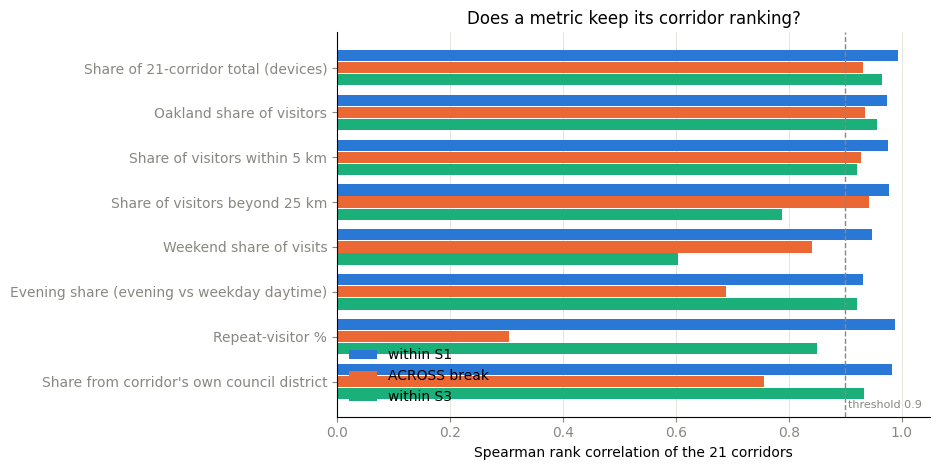

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
metrics = list(rank_table.index)
y = np.arange(len(metrics))
ax.barh(y - 0.27, rank_table["within S1 (H2 21 vs 22)"].astype(float), height=0.25, color=CATEGORICAL_PALETTE[0], label="within S1")
ax.barh(y, rank_table["ACROSS break (H2 22 vs 23)"].astype(float), height=0.25, color=CATEGORICAL_PALETTE[1], label="ACROSS break")
ax.barh(y + 0.27, rank_table["within S3 (H2 24 vs 25)"].astype(float), height=0.25, color=CATEGORICAL_PALETTE[2], label="within S3")
ax.axvline(RANK_OK_THRESHOLD, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
ax.text(RANK_OK_THRESHOLD + 0.005, len(metrics) - 0.4, f"threshold {RANK_OK_THRESHOLD}", color=CHART_MUTED_TEXT, fontsize=8)
ax.set_yticks(y, metrics)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("Spearman rank correlation of the 21 corridors")
ax.set_title("Does a metric keep its corridor ranking?")
ax.legend(frameon=False, loc="lower left")
style_axis(ax, "x")
plt.tight_layout()
plt.show()

**Reading this.** Metrics that clear the threshold (the ranking across the break is nearly as stable as inside a segment)
are tagged `peer_relative`: for these the dashboard can report each corridor's *position among its peers* in each
segment, and the *change in position* between segments is meaningful. Metrics below the threshold are tagged
`within_segment_only` and are never compared across the break.

Note the median-shift column: even metrics that pass have a large **common shift** at the break (for example the Oakland
share is several points higher in S3 for the median corridor) and the spread across corridors differs between
segments. So we do **not** compare raw values across the break even for passing metrics; we compare *rank position*
(and the gap to the median corridor *inside* each segment). The 95% intervals are wide because there are only 21 corridors.

## 4. Do S1 and S3 agree on *where* visitors live?

The pooled origin maps average S1 and S3 shares with equal weights. That is defensible only if the two segments
agree about *which block groups* send visitors, beyond what chance would produce. Test: for each corridor, take the
Spearman correlation across the 354 Oakland block groups between two **halves** of the data:

- **within a segment**: its H1 half-years vs its H2 half-years (both halves have the same provider);
- **across segments**: S1's H1 vs S3's H1, and S1's H2 vs S3's H2 (season matched).

If across-segment agreement is about as high as within-segment agreement, the provider change adds no systematic
geographic distortion and pooling is safe.

,within S1 (H1 vs H2),within S3 (H1 vs H2),across: S1 H1 vs S3 H1,across: S1 H2 vs S3 H2,within S1 (2019-20 vs 2021-22),within S3 (2023H2-24 vs 2025),across (S1 all vs S3 all)
min,0.68,0.80,0.43,0.45,0.46,0.78,0.50
25%,0.91,0.93,0.63,0.67,0.73,0.92,0.67
median,0.95,0.96,0.75,0.77,0.79,0.95,0.78
75%,0.96,0.97,0.85,0.85,0.87,0.96,0.86
max,0.98,0.99,0.92,0.93,0.93,0.98,0.94


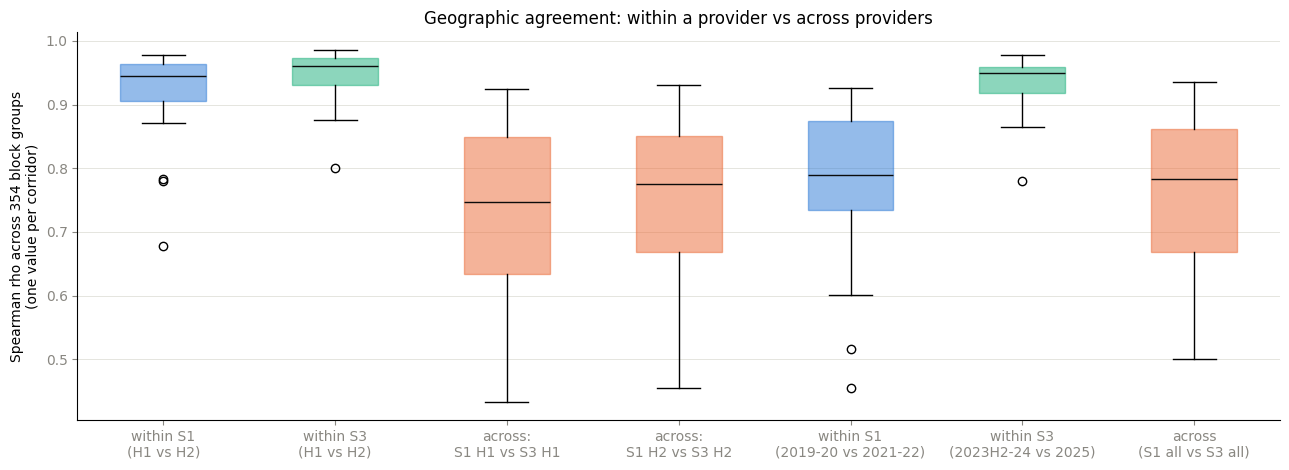

Median per-corridor Spearman rho across the 354 block groups:
  within_a_segment_halves_H1_vs_H2     0.95
  within_a_segment_early_vs_late       0.89
  across_segments_season_matched       0.76
  across_segments_all_years            0.78


In [12]:
shares = {(seg, half): bg_share(homes[(homes.segment == seg) & (homes.half == half)]) for seg in ["S1", "S3"] for half in ["H1", "H2"]}


def per_corridor_rho(a, b):
    return pd.Series({s: spearmanr(a.loc[s], b.loc[s])[0] for s in slugs})


# time-gap matched within-segment benchmarks: early vs late years inside one segment (these include real change over time, like the cross-break pairs)
early_late = {
    "within S1 (2019-20 vs 2021-22)": (bg_share(homes[(homes.segment == "S1") & (homes.year <= "2020")]), bg_share(homes[(homes.segment == "S1") & (homes.year >= "2021")])),
    "within S3 (2023H2-24 vs 2025)": (bg_share(homes[(homes.segment == "S3") & (homes.year <= "2024")]), bg_share(homes[(homes.segment == "S3") & (homes.year == "2025")])),
    "across (S1 all vs S3 all)": (bg_share(homes[homes.segment == "S1"]), bg_share(homes[homes.segment == "S3"])),
}

reliability = pd.DataFrame({
    "within S1 (H1 vs H2)": per_corridor_rho(shares[("S1", "H1")], shares[("S1", "H2")]),
    "within S3 (H1 vs H2)": per_corridor_rho(shares[("S3", "H1")], shares[("S3", "H2")]),
    "across: S1 H1 vs S3 H1": per_corridor_rho(shares[("S1", "H1")], shares[("S3", "H1")]),
    "across: S1 H2 vs S3 H2": per_corridor_rho(shares[("S1", "H2")], shares[("S3", "H2")]),
    **{k: per_corridor_rho(*v) for k, v in early_late.items()},
})
display(reliability.describe().loc[["min", "25%", "50%", "75%", "max"]].rename(index={"50%": "median"}).round(2))

fig, ax = plt.subplots(figsize=(13, 4.8))
bp = ax.boxplot([reliability[c] for c in reliability], tick_labels=[c.replace(" (", "\n(").replace(": ", ":\n") for c in reliability], patch_artist=True, medianprops={"color": "#0b0b0b"})
for b, color in zip(bp["boxes"], [CATEGORICAL_PALETTE[0], CATEGORICAL_PALETTE[2], CATEGORICAL_PALETTE[1], CATEGORICAL_PALETTE[1], CATEGORICAL_PALETTE[0], CATEGORICAL_PALETTE[2], CATEGORICAL_PALETTE[1]]):
    b.set(facecolor=color, alpha=0.5, edgecolor=color)
ax.set_ylabel("Spearman rho across 354 block groups\n(one value per corridor)")
ax.set_title("Geographic agreement: within a provider vs across providers")
style_axis(ax)
plt.tight_layout()
plt.show()

rho_summary = {
    "within_a_segment_halves_H1_vs_H2": float(pd.concat([reliability.iloc[:, 0], reliability.iloc[:, 1]]).median()),
    "within_a_segment_early_vs_late": float(pd.concat([reliability.iloc[:, 4], reliability.iloc[:, 5]]).median()),
    "across_segments_season_matched": float(pd.concat([reliability.iloc[:, 2], reliability.iloc[:, 3]]).median()),
    "across_segments_all_years": float(reliability.iloc[:, 6].median()),
}
print("Median per-corridor Spearman rho across the 354 block groups:")
for k, v in rho_summary.items():
    print(f"  {k:36s} {v:.2f}")

**Reading this.** The fair benchmark for "how well should two periods agree?" is not two halves of the *same* years
(which is easy) but two periods inside one segment that are as far apart in time as S1 and S3 (early vs late years:
median rho about 0.89). Across segments the agreement is lower (about 0.77), so roughly **0.1 of rho** is lost to
the provider change (or to the longer elapsed time and real change, which cannot be separated). The segments therefore
agree on the broad geography but not on fine detail.

What this means for the product: the **default map is the equal-weight blend of S1 and S3** (each provider has the same
say and no scaling between providers is needed), but because the blend hides a real, moderate disagreement, the data
also carry **each segment's own map** (2019-22 and 2023-25) so a reader can see both. Neither is calibrated to the
other, and differences between the two maps are read as "within-provider patterns that differ", not as measured change.

## 5. Break band parameters and rules

The band drawn across the break for *share of the 21-corridor total* is `x / exp(s)` to `x * exp(s)`, where `s` is the
**excess spread** from section 2 (the cross-break spread beyond ordinary within-segment spread). It is one robust
standard deviation, so roughly two thirds of corridors would be expected inside it if the excess were all provider
effect and roughly normal; because it also contains real change it is a conservative band.

In [13]:
share_row = level_table.loc["Share of 21-corridor total (devices)"]
dev_row = level_table.loc["Estimated devices (level)"]

comparability = {
    "rank_ok_threshold": RANK_OK_THRESHOLD,
    "segments_used": ["S1", "S3"],
    "segments_excluded": {"S2": "Jan-Jun 2023; reference panel ~17k devices, a few hundred device-months per corridor"},
    "windows": {"break": "H2 2022 -> H2 2023", "within_s1": "H2 2021 -> H2 2022", "within_s3": "H2 2024 -> H2 2025"},
    "level": {
        "devices": {"median_ratio_break": float(dev_row["median x ACROSS break"]), "within_sd_log": float(dev_row["spread within (robust SD, log)"]),
                    "break_sd_log": float(dev_row["spread across break"]), "excess_sd_log": float(dev_row["excess spread"])},
        "share_of_total": {"within_sd_log": float(share_row["spread within (robust SD, log)"]), "break_sd_log": float(share_row["spread across break"]),
                           "excess_sd_log": float(share_row["excess spread"])},
    },
    "rank_stability": {
        m: {"s1_within": float(r["within S1 (H2 21 vs 22)"]), "break": float(r["ACROSS break (H2 22 vs 23)"]),
            "break_ci": r["95% CI (bootstrap)"], "s3_within": float(r["within S3 (H2 24 vs 25)"]), "rule": r["rule"]}
        for m, r in rank_table.iterrows()
    },
    "pooling_reliability": rho_summary,
}
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
with open(COMPARABILITY_JSON, "w") as f:
    json.dump(comparability, f, indent=2)
print(f"Wrote {COMPARABILITY_JSON.relative_to(ROOT)}")
print(f"\nBand for share-of-total across the break: x / {np.exp(share_row['excess spread']):.2f} to x * {np.exp(share_row['excess spread']):.2f}")
print("Rules:")
for m, r in comparability["rank_stability"].items():
    print(f"  {r['rule']:20s} {m}  (break rho {r['break']:.2f})")

Wrote data/activity/processed/comparability.json

Band for share-of-total across the break: x / 1.42 to x * 1.42
Rules:
  peer_relative        Share of 21-corridor total (devices)  (break rho 0.93)
  peer_relative        Oakland share of visitors  (break rho 0.94)
  peer_relative        Share of visitors within 5 km  (break rho 0.93)
  peer_relative        Share of visitors beyond 25 km  (break rho 0.94)
  within_segment_only  Weekend share of visits  (break rho 0.84)
  within_segment_only  Evening share (evening vs weekday daytime)  (break rho 0.69)
  within_segment_only  Repeat-visitor %  (break rho 0.31)
  within_segment_only  Share from corridor's own council district  (break rho 0.76)


## Summary of the decisions this notebook supports

| Question | Evidence | Decision |
|---|---|---|
| Use S2? | ~17k-device panel, a few hundred devices per corridor-month | **Exclude** everywhere; show gaps |
| Compare activity levels across the break? | Provider effect is not a common multiplier: cross-break spread is several times the within-segment spread (section 2) | **No raw levels.** Show S1 and S3 as separate lines; compare across the break only as *share of the 21-corridor total* (rank holds, rho ~0.93), with the band above |
| Compare other metrics across the break? | Rank-stability table (section 3) | Pass (rho >= 0.9): share of total, Oakland share, within 5 km, beyond 25 km -> **peer position** (rank and gap to the median corridor, per segment). Fail: weekend share, evening share, repeat %, own-district share -> **within-segment only** |
| Pool S1 and S3 origin shares for the map? | Across-segment geographic agreement ~0.77 vs ~0.89 for time-matched halves inside a segment (section 4) | Default = equal-weight blend; **also publish S1-only and S3-only maps**. Never mix counts across providers |

What the data **cannot** say: "corridor X in 2025 is at N% of its 2019 level". That needs an absolute bridge across the
break, and there is no overlap period to estimate one.